In [1]:
import os
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import numpy as np

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


In [2]:
#Feature
def generate_batch(batch_size, S, n):
    input1 = torch.rand(batch_size, n)
    input2 = torch.rand(batch_size, n)
    dataset = input1 * torch.gt(input2, S).float()
    return dataset

In [3]:
# Neural Network Model
class NeuralNetwork(nn.Module):
    def __init__(self, n, m, activation):
        super(NeuralNetwork, self).__init__()
        self.n = n
        self.m = m
        self.weight = nn.init.xavier_normal_(torch.rand(m, n))
        self.bias = torch.zeros(n)
        self.activation = activation
        self.weight = nn.Parameter(self.weight)
        self.bias = nn.Parameter(self.bias)


    def forward(self, x):
        h = torch.matmul(x, self.weight.t())
        x_prime = self.activation(torch.matmul(h, self.weight) + self.bias)
        return x_prime
    

In [4]:
n = 5 # number of input features
m = 2 # number of hidden units
importance = torch.arange(0, n).float()  # importance of each feature
importance = torch.pow(0.7, importance)  # apply a power transformation to the importance values
def loss_fn (x, x_prime, importance):
    return torch.sum(importance * (x - x_prime) ** 2, dim=1).mean()
# m < n to ensure that the model is underparameterized
model = NeuralNetwork(n, m, nn.ReLU())
dataset = generate_batch(3, 0, n)

In [5]:
# Training loop model function
def train_model(n, batch_size, S, model, importance, epochs=7000, learning_rate=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate)
    for epoch in range(epochs):
        dataset = generate_batch(batch_size, S, n)
        optimizer.zero_grad()
        x_prime = model(dataset)
        loss = loss_fn(dataset, x_prime, importance)
        loss.backward()
        optimizer.step()
        if epoch == epochs - 1:
            weight = model.weight.detach().clone().numpy()
    print(S, loss.item())
    return weight

0.9 0.004241862799972296
W: [-1.0061146020889282, 1.0062240362167358]


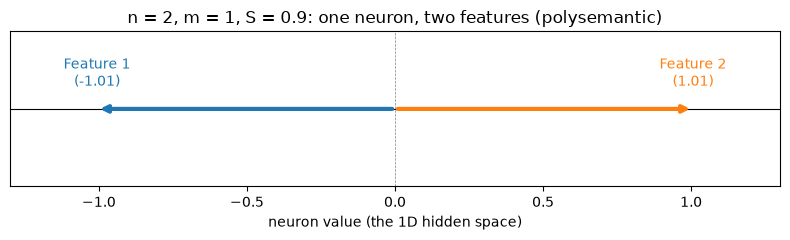

In [6]:
# Two features weight vector test to show superposition of features in the hidden layer
n = 2 # number of input features
m = 1 # number of hidden units
batch_size = 1000
importance = torch.ones(n).float()  # importance of each feature
S = 0.9 # threshold for generating the dataset
torch.manual_seed(3)  # Set the random seed for reproducibility
model_1 = NeuralNetwork(n, m, nn.ReLU())
W = train_model(n, batch_size, S, model_1, importance)

import matplotlib.pyplot as plt

w = model_1.weight.detach().flatten().tolist()   # 2 numbers: feature 1, feature 2
print("W:", w)   # check this is roughly [a, -a] before trusting the plot

fig, ax = plt.subplots(figsize=(8, 2.5))
ax.axhline(0, color="black", lw=0.8)              # the neuron's 1D space
ax.axvline(0, color="grey", lw=0.5, ls="--")      # origin

colors = ["tab:blue", "tab:orange"]
for i in range(2):
    # arrow goes FROM xytext (origin) TO xy (the feature's weight)
    ax.annotate("", xy=(w[i], 0), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color=colors[i], lw=3))
    ax.text(w[i], 0.12, f"Feature {i+1}\n({w[i]:.2f})",
            ha="center", color=colors[i])

ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-0.4, 0.4)
ax.set_yticks([])
ax.set_xlabel("neuron value (the 1D hidden space)")
ax.set_title(f"n = 2, m = 1, S = {S}: one neuron, two features (polysemantic)")
plt.tight_layout()
fig.savefig("polysemantic_1d.png", dpi=300)
plt.show()

In [7]:
# Larger feature weight vector test to show superposition of features in the hidden layer
n = 20 # number of input features
m = 5 # number of hidden units
importance = torch.arange(0, n).float()  # importance of each feature
importance = torch.pow(0.7, importance)  # apply a power transformation to the importance values
S_list = [0, 0.7, 0.9, 0.97, 0.99, 0.997, 0.999] # thresholds for generating the dataset
relu = {}
for S in S_list:
    for i in range(3):  # Run over 3 seeds for each S value
        model_relu = NeuralNetwork(n, m, nn.ReLU())
        torch.manual_seed(i)  # Set the seed for reproducibility
        train_model(n, batch_size, S, model_relu, importance)
        if S == 0.7 and i == 1:  # Store the weights only for the second seed of S=0.7 to avoid overwriting
            relu[S] = model_relu.weight.detach().clone().numpy()  # Store the weights for S=0.7
        elif i == 0:  # Store the weights only for the first seed to avoid overwriting
            relu[S] = model_relu.weight.detach().clone().numpy()  # Store the weights for each S value

0 0.04643360152840614
0 0.046450238674879074
0 0.04758063703775406
0.7 0.03740257769823074
0.7 0.03711389750242233
0.7 0.03741519898176193
0.9 0.008508245460689068
0.9 0.008546687662601471
0.9 0.009073934517800808
0.97 0.001442721113562584
0.97 0.0016993522876873612
0.97 0.0015163689386099577
0.99 0.0002558163250796497
0.99 0.0002299561892868951
0.99 0.0002782856463454664
0.997 6.649899296462536e-05
0.997 7.554161857115105e-05
0.997 9.013387170853093e-05
0.999 2.9044062102911994e-05
0.999 2.88399460259825e-05
0.999 4.1600840631872416e-05


In [8]:
linear = {}
for S in S_list:
    for i in range(3):  # Run over 3 seeds for each S value
        model_linear = NeuralNetwork(n, m, nn.Identity())
        torch.manual_seed(i)  # Set the seed for reproducibility
        train_model(n, batch_size, S, model_linear, importance)
        if S == 0.7 and i == 1:  # Store the weights only for the second seed of S=0.7 to avoid overwriting
            linear[S] = model_linear.weight.detach().clone().numpy()  # Store the weights for S=0.7
        elif i == 0:  # Store the weights only for the first seed to avoid overwriting
            linear[S] = model_linear.weight.detach().clone().numpy()  # Store the weights for each S value


0 0.0464324876666069
0 0.046447888016700745
0 0.04757770523428917
0.7 0.043327443301677704
0.7 0.043102096766233444
0.7 0.04394631087779999
0.9 0.01694459281861782
0.9 0.016952969133853912
0.9 0.01741652935743332
0.97 0.005126865580677986
0.97 0.005410292185842991
0.97 0.0056130411103367805
0.99 0.0017065064748749137
0.99 0.0015880631981417537
0.99 0.0019984690006822348
0.997 0.00028278736863285303
0.997 0.00032866658875718713
0.997 0.0004391377151478082
0.999 7.087711856001988e-05
0.999 8.57753911986947e-05
0.999 0.00014146833564154804


In [9]:
print(relu)

print(linear)
torch.allclose(torch.tensor(relu[0]), torch.tensor(relu[0.999]))  # Check if the weights for S=0 and S=0.999 are close

{0: array([[ 4.81463134e-01, -1.68767869e-01,  4.10302952e-02,
         5.46839356e-01,  6.62738919e-01,  2.00267439e-03,
         3.42555431e-04,  9.27073881e-04, -2.85538915e-03,
        -5.58682135e-04, -4.61560441e-04,  6.66735927e-04,
        -5.02406074e-05,  3.69823538e-04, -2.93938356e-04,
         2.89566495e-04,  1.26033512e-04,  1.07228021e-04,
        -3.28303868e-05, -2.86280047e-05],
       [ 8.36409509e-01,  2.56405592e-01, -2.50560015e-01,
        -3.22150201e-01, -2.61015713e-01, -1.95325259e-03,
        -1.30561972e-03,  4.45492769e-04,  1.35132170e-04,
         2.59408785e-04,  4.85508994e-04, -2.26292395e-04,
         3.43933993e-04, -2.49271048e-04,  4.82620053e-05,
        -1.04951199e-04,  1.87845275e-04,  2.73968562e-05,
         1.07487685e-04,  6.65753978e-05],
       [ 7.78076500e-02,  5.31118631e-01,  5.31274736e-01,
         5.27284384e-01, -3.89167368e-01,  1.91704580e-03,
         2.35881447e-03,  2.21770816e-03, -1.00657390e-03,
        -7.37606751e-06, 

False

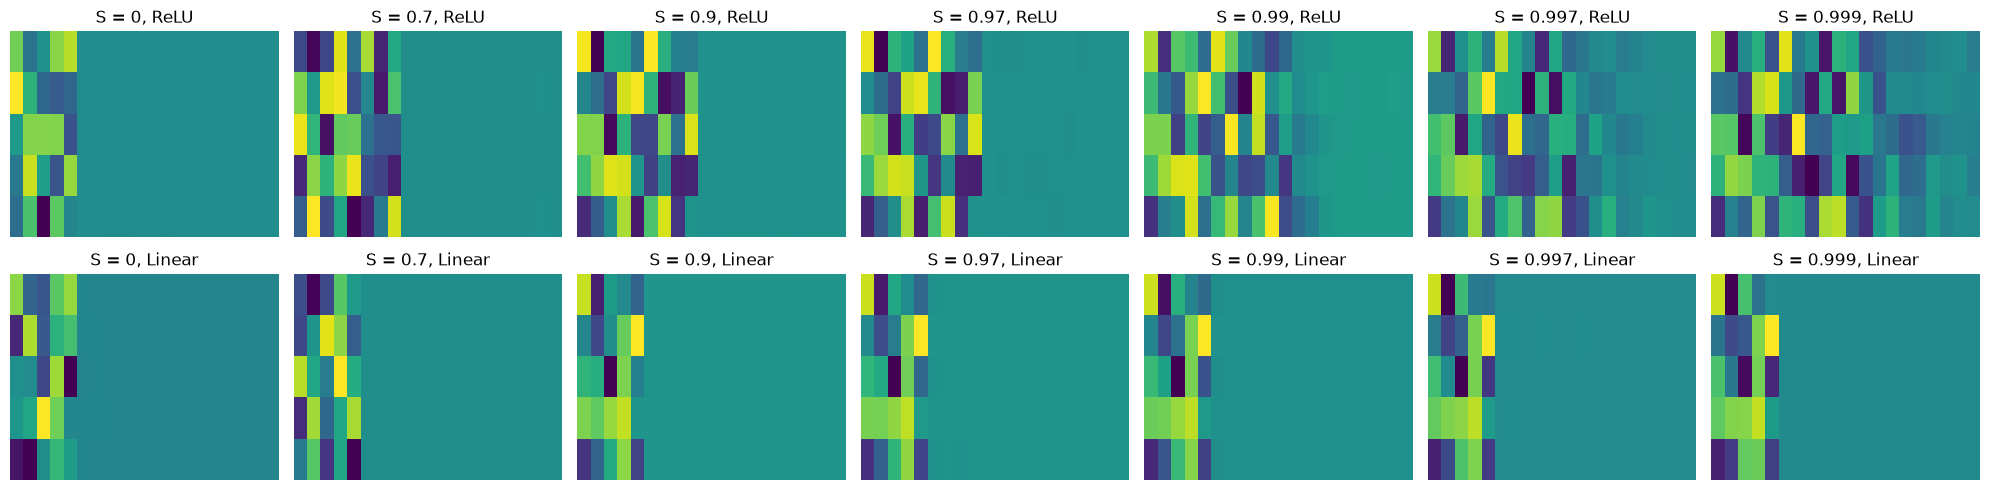

In [10]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2,7, figsize=(20, 5))
for i, S in enumerate(relu.keys()):
    axs[0, i].imshow(relu[S], cmap='viridis', aspect='auto')
    axs[0, i].set_title(f'S = {S}, ReLU')
    axs[0, i].axis('off')

    axs[1, i].imshow(linear[S], cmap='viridis', aspect='auto')
    axs[1, i].set_title(f'S = {S}, Linear')
    axs[1, i].axis('off')

plt.tight_layout()
plt.savefig('superposition_weights_map.png')
plt.show()

/tmp/ipykernel_144748/3264427947.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


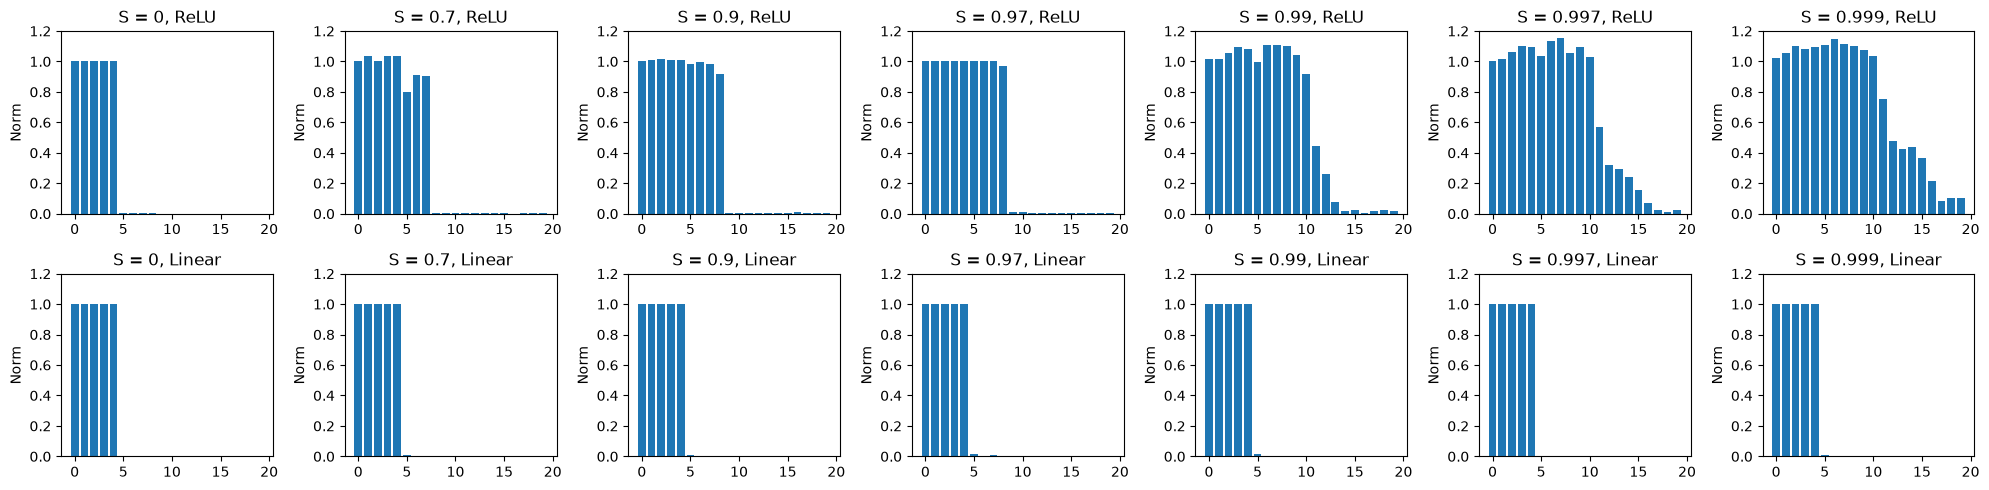

In [11]:
plt, axs = plt.subplots(2,7, figsize=(20, 5))
for i, S in enumerate(relu.keys()):
    R = torch.linalg.norm(torch.tensor(relu[S]), dim = 0)
    axs[0, i].set_ylim(0, 1.2)
    axs[0, i].bar(range(len(R)), R)
    axs[0, i].set_title(f'S = {S}, ReLU')

    axs[0, i].set_ylabel('Norm')

    L = torch.linalg.norm(torch.tensor(linear[S]), dim = 0)
    axs[1, i].set_ylim(0, 1.2)
    axs[1, i].bar(range(len(L)), L)
    axs[1, i].set_title(f'S = {S}, Linear')
    axs[1, i].set_ylabel('Norm')
plt.tight_layout()
plt.savefig('superposition_weights_bar.png', dpi=300)
plt.show()